# Eigenvalue Stability Analysis — Routh-Hurwitz (Non-Linear ODE, Disease-Free Equilibrium)
**Author:** Achyutan Veeraraghavan
**Mentor:** Dr. Padmanabhan Seshaiyer (George Mason University)

## Model overview
Four-compartment **NON-LINEAR** ODE system (N, L, M, H) with social-contagion products. Local stability of the disease-free equilibrium (DFE) is analyzed as a function of $\alpha_w$ using the Routh-Hurwitz criterion on the Jacobian at the DFE (slides 7–8).

| Compartment | Meaning |
|---|---|
| $N(t)$ | No risk (protected via education) |
| $L(t)$ | Low risk (susceptible) |
| $M(t)$ | Medium risk |
| $H(t)$ | High risk |

**Control:** composite intervention intensity $\alpha_w$, decomposed with fixed weights into $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$.

$$\frac{dN}{dt} = \alpha L - \delta N \qquad \frac{dL}{dt} = -\beta_1 LM - \beta_1 LH + \gamma_1 M - \alpha L + \delta N$$
$$\frac{dM}{dt} = \beta_1 LM + \beta_1 LH - \beta_2 MH - \gamma_1 M + \gamma_2 H \qquad \frac{dH}{dt} = \beta_2 MH - \gamma_2 H$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Section 1 — Parameters

In [2]:
# =============================================================================
# PARAMETERS
# =============================================================================
beta1   = 0.15
beta2   = 0.10
delta   = 0.02
v_alpha = 0.40
v1      = 0.35
v2      = 0.25
alpha_max = 1.0

alpha_w  = np.linspace(0, alpha_max, 2000)
alpha_t  = v_alpha * alpha_w
gamma1_t = v1      * alpha_w
gamma2_t = v2      * alpha_w

## Section 2 — Disease-free equilibrium (slide 7)

$$M^* = H^* = 0, \qquad L^* = \frac{\delta}{\alpha+\delta}, \qquad N^* = \frac{\alpha}{\alpha+\delta}$$

Shorthand used on slide 7: $T = \gamma_1 - \beta_1 L^*$ (called `Gamma` in the code). The critical eigenvalue is $\lambda_e = -T = \beta_1 L^* - \gamma_1$.

In [3]:
# DFE compartment values
L_DFE = delta / (alpha_t + delta)
N_DFE = 1.0 - L_DFE

# Gamma = gamma1 - beta1*L*_DFE (key structural term)
Gamma    = gamma1_t - beta1 * L_DFE
lambda_e = -Gamma   # critical eigenvalue at DFE

## Section 3 — Jacobian at the DFE and characteristic polynomial (slide 7)

$$J_{DFE} = \begin{pmatrix} -\delta & \alpha & 0 & 0\\ \delta & -\alpha & -\beta_1 L^* + \gamma_1 & -\beta_1 L^*\\ 0 & 0 & \beta_1 L^* - \gamma_1 & \beta_1 L^* + \gamma_2\\ 0 & 0 & 0 & -\gamma_2 \end{pmatrix}$$

$$\det(\lambda_e I - J_{DFE}) = \lambda_e^4 + A_1\lambda_e^3 + A_2\lambda_e^2 + A_3\lambda_e + A_4 = 0, \qquad A_4 = 0 \;\rightarrow\; \lambda_{e1} = 0$$

$$A_1 = \delta + \alpha + T + \gamma_2 \qquad A_3 = \delta T\gamma_2$$
$$A_2 = \delta\alpha + \delta T + \delta\gamma_2 + \alpha T + \alpha\gamma_2 + T\gamma_2$$

**Routh-Hurwitz conditions** (all must hold for every non-zero eigenvalue to have $\mathrm{Re}(\lambda_e) < 0$):

1. $A_1 > 0$
2. $A_2 > 0$
3. $A_3 > 0$
4. $A_1A_2 - A_3 > 0$

$A_3 > 0 \iff T > 0 \iff \gamma_1 > \beta_1 L^*$, so condition 3 is the binding one.

In [4]:
# =============================================================================
# ROUTH-HURWITZ COEFFICIENTS FROM DFE JACOBIAN
# =============================================================================
A1 = delta + alpha_t + Gamma + gamma2_t

A2 = (delta * alpha_t
      + delta * Gamma
      + delta * gamma2_t
      + alpha_t * Gamma
      + alpha_t * gamma2_t
      + Gamma * gamma2_t)

A3  = delta * Gamma * gamma2_t
RH4 = A1 * A2 - A3

## Section 4 — Stability switch

Setting $\lambda_e = 0$: $\dfrac{\beta_1\delta}{v_\alpha\alpha_w + \delta} = v_1\alpha_w \;\rightarrow\; v_1 v_\alpha\alpha_w^2 + v_1\delta\alpha_w - \beta_1\delta = 0$, solved with the quadratic formula (positive root).

In [5]:
# DFE stability switch: solve lambda_e = 0
# beta1*delta/(v_alpha*aw+delta) = v1*aw
# -> v1*v_alpha*aw^2 + v1*delta*aw - beta1*delta = 0
a_c = v1 * v_alpha
b_c = v1 * delta
c_c = -beta1 * delta
alpha_w_crit = (-b_c + np.sqrt(b_c**2 - 4*a_c*c_c)) / (2*a_c)

## Section 5 — Numerical eigenvalues (reference check)

In [6]:
# Numerical eigenvalues for reference
def compute_eigenvalues_dfe(aw):
    a  = v_alpha * aw
    g1 = v1 * aw
    g2 = v2 * aw
    Ld = delta / (a + delta)
    J = np.array([
        [-delta,   a,              0,              0       ],
        [ delta,  -a,  -beta1*Ld+g1,      -beta1*Ld       ],
        [     0,   0,   beta1*Ld-g1,   beta1*Ld+g2        ],
        [     0,   0,           0,           -g2           ]
    ])
    return np.sort(np.real(np.linalg.eigvals(J)))

eigs_0    = compute_eigenvalues_dfe(0.001)
eigs_crit = compute_eigenvalues_dfe(alpha_w_crit)
eigs_max  = compute_eigenvalues_dfe(alpha_max)

## Section 6 — Results

In [7]:
# =============================================================================
# PRINT KEY RESULTS
# =============================================================================
print("=" * 60)
print("NONLINEAR MODEL — DFE ROUTH-HURWITZ STABILITY RESULTS")
print("=" * 60)
for label, idx in [("α_w = 0.0", 0), ("α_w = 1.0", -1)]:
    print(f"\nAt {label}:")
    print(f"  lambda_e  = {lambda_e[idx]:.4f}  {'< 0 ✓ stable' if lambda_e[idx]<0 else '> 0 ✗ unstable'}")
    print(f"  A1        = {A1[idx]:.4f}  {'> 0 ✓' if A1[idx]>0 else '≤ 0 ✗'}")
    print(f"  A2        = {A2[idx]:.6f}  {'> 0 ✓' if A2[idx]>0 else '≤ 0 ✗'}")
    print(f"  A3        = {A3[idx]:.6f}  {'> 0 ✓' if A3[idx]>0 else '≤ 0 ✗'}")
    print(f"  A1*A2-A3  = {RH4[idx]:.6f}  {'> 0 ✓' if RH4[idx]>0 else '≤ 0 ✗'}")
print(f"\nDFE stability switch at α_w = {alpha_w_crit:.4f}")
print(f"  Eigenvalues at switch: {compute_eigenvalues_dfe(alpha_w_crit)}")

NONLINEAR MODEL — DFE ROUTH-HURWITZ STABILITY RESULTS

At α_w = 0.0:
  lambda_e  = 0.1500  > 0 ✗ unstable
  A1        = -0.1300  ≤ 0 ✗
  A2        = -0.003000  ≤ 0 ✗
  A3        = -0.000000  ≤ 0 ✗
  A1*A2-A3  = 0.000390  > 0 ✓

At α_w = 1.0:
  lambda_e  = -0.3429  < 0 ✓ stable
  A1        = 1.0129  > 0 ✓
  A2        = 0.342714  > 0 ✓
  A3        = 0.001714  > 0 ✓
  A1*A2-A3  = 0.345406  > 0 ✓

DFE stability switch at α_w = 0.1235
  Eigenvalues at switch: [-6.94017797e-02 -3.08761123e-02 -1.38777878e-17  0.00000000e+00]


## Section 7 — Figure (slide 8)

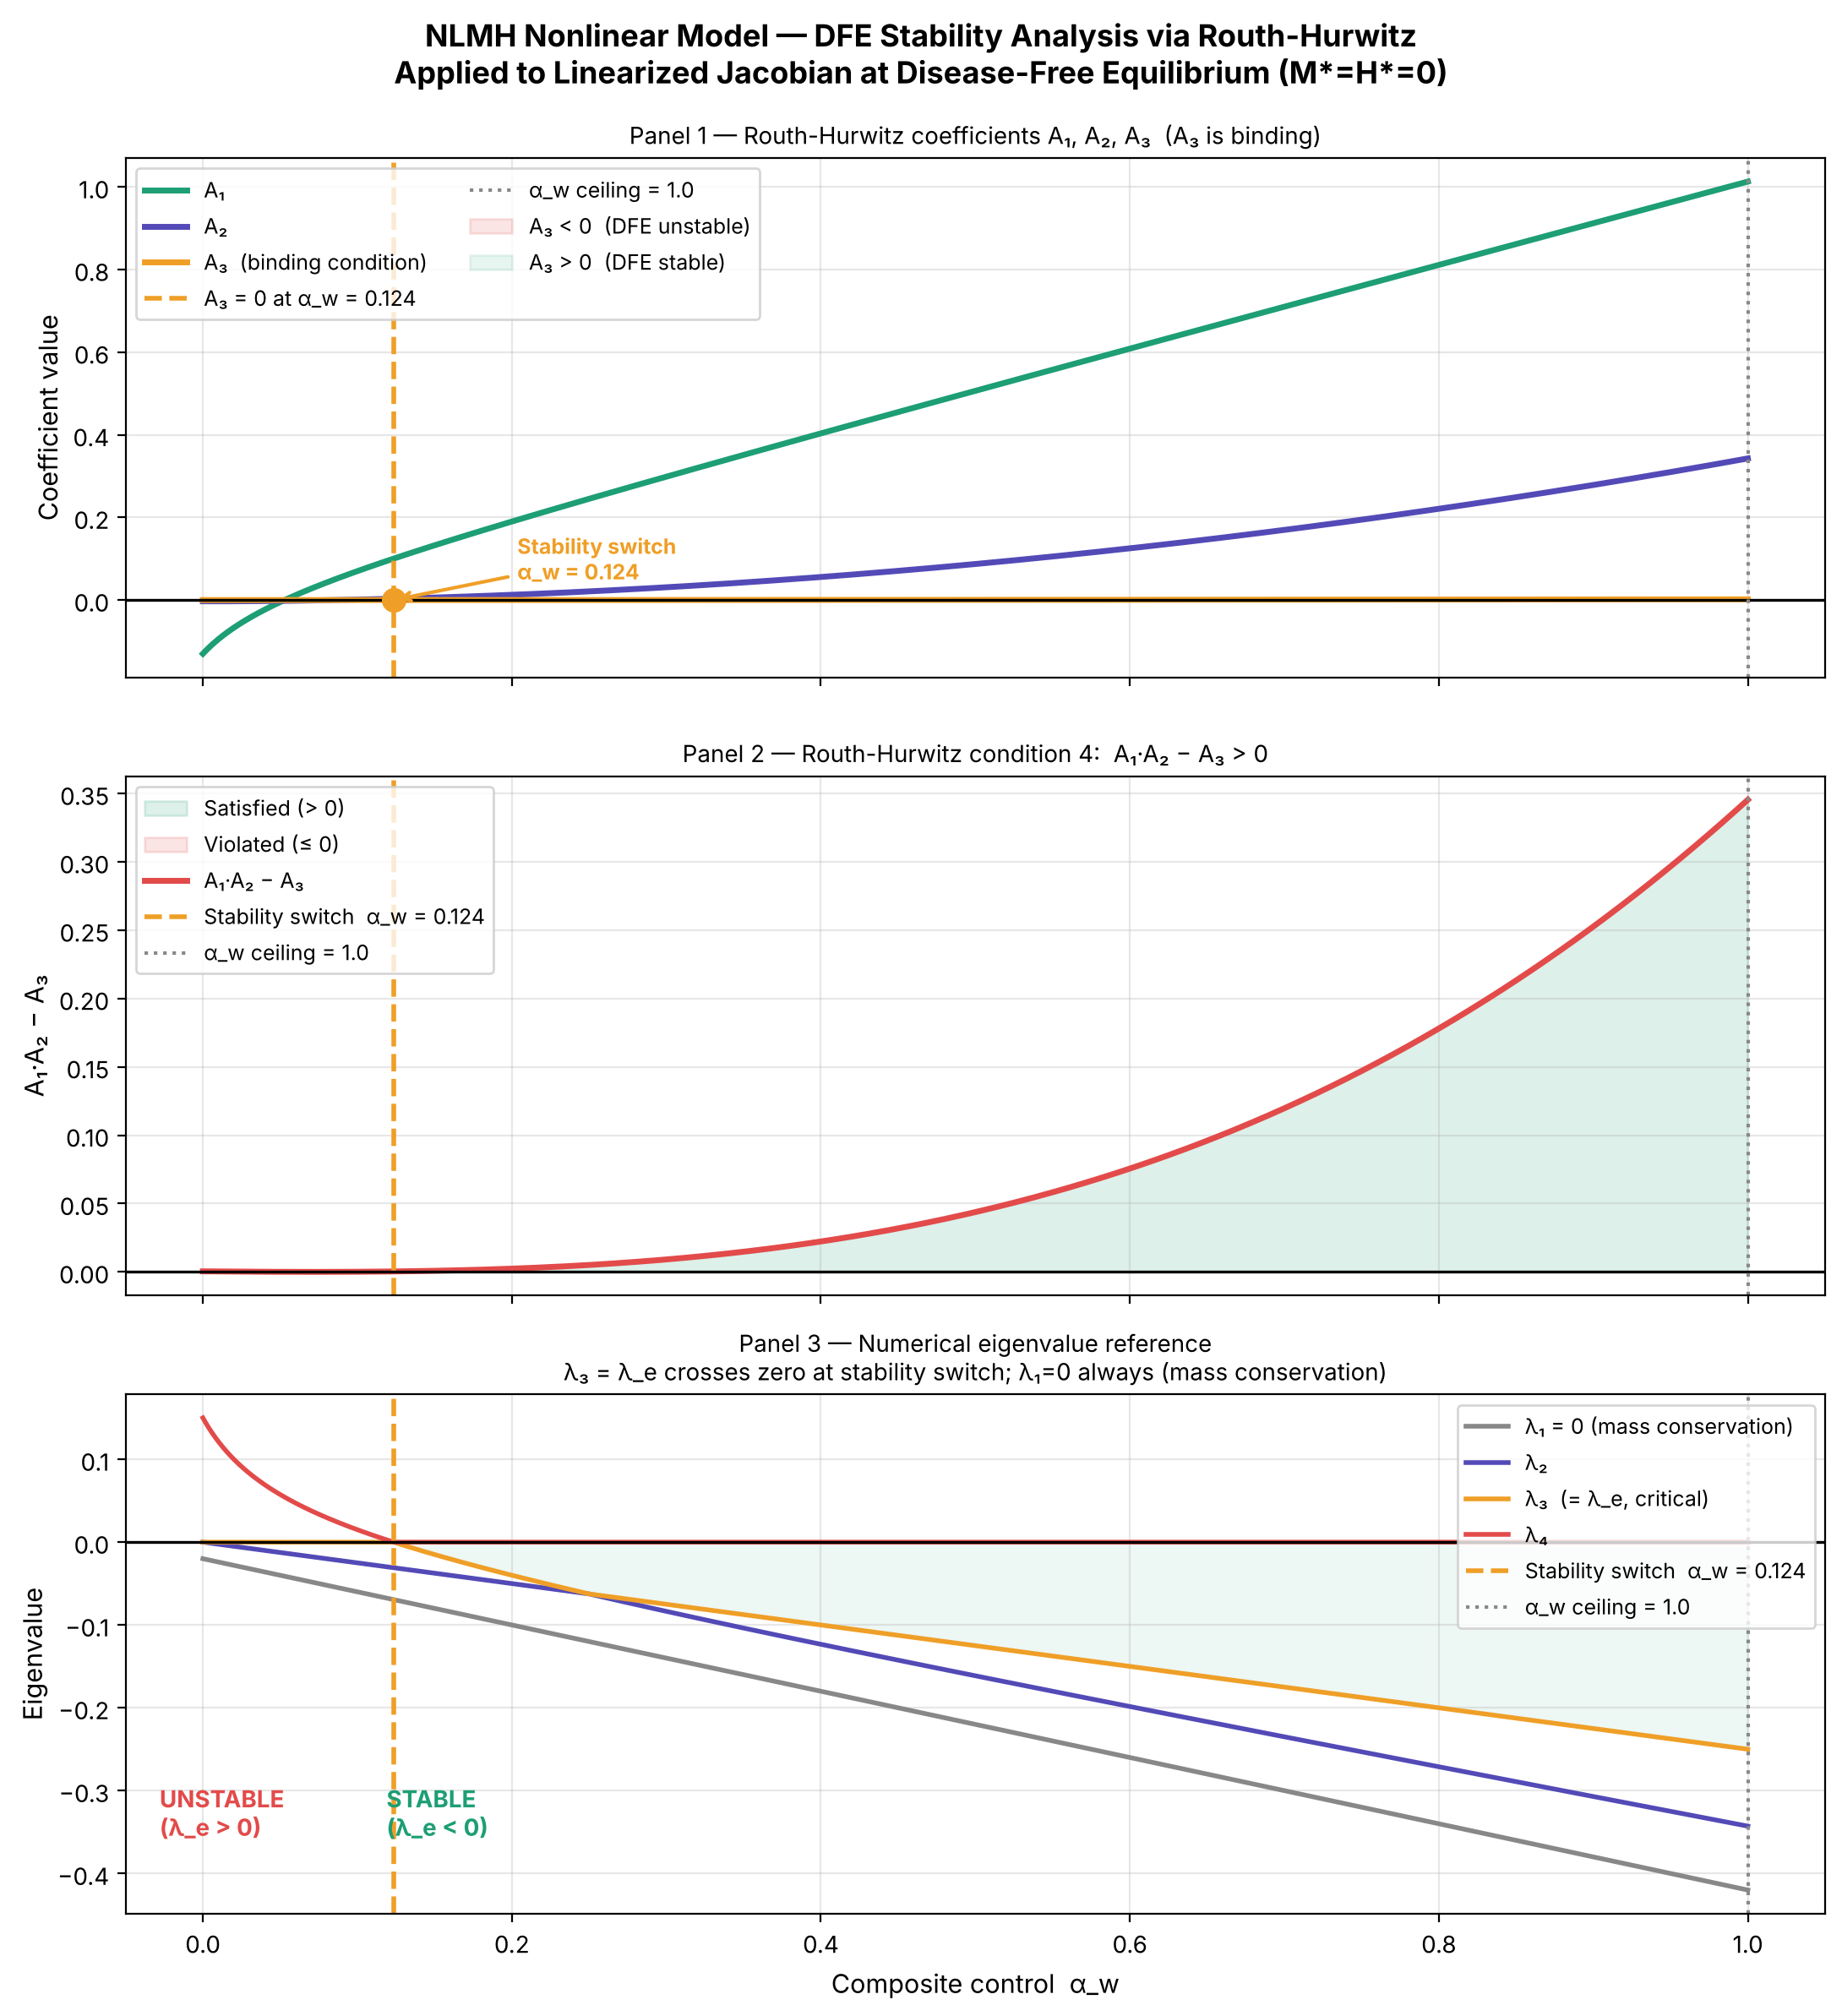


Figure saved: nlmh_stability_nonlinear_dfe.png


In [8]:
# =============================================================================
# FIGURE — 3 PANELS (standardized layout matching linear script)
# Panel 1: A1, A2, A3 combined
# Panel 2: A1*A2 - A3 (condition 4)
# Panel 3: Numerical eigenvalue reference
# =============================================================================
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
fig.suptitle(
    "NLMH Nonlinear Model — DFE Stability Analysis via Routh-Hurwitz\n"
    "Applied to Linearized Jacobian at Disease-Free Equilibrium (M*=H*=0)",
    fontsize=13, fontweight='bold', y=0.99
)

# ── Panel 1: A1, A2, A3 ─────────────────────────────────────────────────────
ax1 = axes[0]
ax1.plot(alpha_w, A1,  color='#1D9E75', linewidth=2.5, label='A₁')
ax1.plot(alpha_w, A2,  color='#534AB7', linewidth=2.5, label='A₂')
ax1.plot(alpha_w, A3,  color='#EF9F27', linewidth=2.5, label='A₃  (binding condition)')
ax1.axhline(0, color='black', linewidth=1.2)
ax1.axvline(alpha_w_crit, color='#EF9F27', linewidth=2.0, linestyle='--',
            label=f'A₃ = 0 at α_w = {alpha_w_crit:.3f}')
ax1.axvline(alpha_max, color='#888888', linewidth=1.5, linestyle=':',
            label=f'α_w ceiling = {alpha_max}')
ax1.scatter([alpha_w_crit], [0], color='#EF9F27', zorder=6, s=90)
ax1.fill_between(alpha_w, A3, 0, where=(A3<0),
                 color='#E24B4A', alpha=0.15, label='A₃ < 0  (DFE unstable)')
ax1.fill_between(alpha_w, A3, 0, where=(A3>=0),
                 color='#1D9E75', alpha=0.10, label='A₃ > 0  (DFE stable)')
ax1.annotate(f'Stability switch\nα_w = {alpha_w_crit:.3f}',
             xy=(alpha_w_crit, 0), xytext=(alpha_w_crit+0.08, 0.05),
             fontsize=9, color='#EF9F27', fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='#EF9F27', lw=1.5))
ax1.set_ylabel("Coefficient value", fontsize=11)
ax1.set_title("Panel 1 — Routh-Hurwitz coefficients A₁, A₂, A₃  (A₃ is binding)", fontsize=10)
ax1.legend(loc='upper left', fontsize=9, ncol=2)
ax1.grid(True, alpha=0.3)

# ── Panel 2: A1*A2 - A3 ─────────────────────────────────────────────────────
ax2 = axes[1]
ax2.fill_between(alpha_w, RH4, 0, where=(RH4>0),
                 color='#1D9E75', alpha=0.15, label='Satisfied (> 0)')
ax2.fill_between(alpha_w, RH4, 0, where=(RH4<=0),
                 color='#E24B4A', alpha=0.15, label='Violated (≤ 0)')
ax2.plot(alpha_w, RH4, color='#E24B4A', linewidth=2.5, label='A₁·A₂ − A₃')
ax2.axhline(0, color='black', linewidth=1.2)
ax2.axvline(alpha_w_crit, color='#EF9F27', linewidth=2.0, linestyle='--',
            label=f'Stability switch  α_w = {alpha_w_crit:.3f}')
ax2.axvline(alpha_max, color='#888888', linewidth=1.5, linestyle=':',
            label=f'α_w ceiling = {alpha_max}')
ax2.set_ylabel("A₁·A₂ − A₃", fontsize=11)
ax2.set_title("Panel 2 — Routh-Hurwitz condition 4:  A₁·A₂ − A₃ > 0", fontsize=10)
ax2.legend(loc='upper left', fontsize=9)
ax2.grid(True, alpha=0.3)

# ── Panel 3: Numerical eigenvalue reference ──────────────────────────────────
ax3 = axes[2]
eig_arr = np.array([compute_eigenvalues_dfe(aw) for aw in alpha_w])
colors_eig = ['#888888', '#534AB7', '#EF9F27', '#E24B4A']
labels_eig = ['λ₁ = 0 (mass conservation)', 'λ₂', 'λ₃  (= λ_e, critical)', 'λ₄']
for j, (col, lab) in enumerate(zip(colors_eig, labels_eig)):
    ax3.plot(alpha_w, eig_arr[:, j], color=col, linewidth=2.0, label=lab)
ax3.axhline(0, color='black', linewidth=1.2)
ax3.axvline(alpha_w_crit, color='#EF9F27', linewidth=2.0, linestyle='--',
            label=f'Stability switch  α_w = {alpha_w_crit:.3f}')
ax3.axvline(alpha_max, color='#888888', linewidth=1.5, linestyle=':',
            label=f'α_w ceiling = {alpha_max}')
ax3.fill_between(alpha_w, eig_arr[:, 2], 0,
                 where=(eig_arr[:,2]>0), color='#E24B4A', alpha=0.12)
ax3.fill_between(alpha_w, eig_arr[:, 2], 0,
                 where=(eig_arr[:,2]<=0), color='#1D9E75', alpha=0.08)
ax3.text(0.02, 0.15, 'UNSTABLE\n(λ_e > 0)',
         transform=ax3.transAxes, color='#E24B4A', fontsize=10, fontweight='bold')
ax3.text(alpha_w_crit/alpha_max + 0.03, 0.15, 'STABLE\n(λ_e < 0)',
         transform=ax3.transAxes, color='#1D9E75', fontsize=10, fontweight='bold')
ax3.set_xlabel("Composite control  α_w", fontsize=11)
ax3.set_ylabel("Eigenvalue", fontsize=11)
ax3.set_title(
    "Panel 3 — Numerical eigenvalue reference\n"
    "λ₃ = λ_e crosses zero at stability switch; λ₁=0 always (mass conservation)",
    fontsize=10
)
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("nlmh_stability_nonlinear_dfe.png", dpi=150)
plt.show()
print("\nFigure saved: nlmh_stability_nonlinear_dfe.png")